## Load libraries

In [ ]:
import polars as pl
import os
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
pl.Config.set_tbl_rows(20)  # show up to 20 rows
import polars.selectors as cs
import seaborn as sns
sns.set_style("darkgrid")  # darkgrid
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

### Read accepted_df

In [ ]:
# Never use CSV again
accepted_df = pl.read_parquet("../data/processed_data/processed_accepted_df.parquet")
accepted_df.head()

FileNotFoundError: The system cannot find the file specified. (os error 2): accepted_2007_to_2018Q4.parquet

In [ ]:
type_summary = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "dtype":  [str(accepted_df[c].dtype) for c in accepted_df.columns],
        "nulls":  [accepted_df[c].is_null().sum() for c in accepted_df.columns],
        "null_pct": [round(accepted_df[c].is_null().sum() / len(accepted_df) * 100, 2) for c in accepted_df.columns],
    })
    .sort("dtype")
)

print(f"Dataset shape: f{len(accepted_df), len(accepted_df.columns)}")
print("\n----- Null Values Distribution -----")
print(type_summary)
print()
print("\n----- Datatype Counts -----")
print(
    type_summary
    .group_by("dtype")
    .agg(pl.count().alias("n_cols"))
    .sort("n_cols", descending=True)
)


Dataset shape: f(2260701, 151)

----- Null Values Distribution -----
shape: (151, 4)
┌───────────────────────────┬─────────┬─────────┬──────────┐
│ column                    ┆ dtype   ┆ nulls   ┆ null_pct │
│ ---                       ┆ ---     ┆ ---     ┆ ---      │
│ str                       ┆ str     ┆ i64     ┆ f64      │
╞═══════════════════════════╪═════════╪═════════╪══════════╡
│ loan_amnt                 ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt               ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt_inv           ┆ Float64 ┆ 33      ┆ 0.0      │
│ int_rate                  ┆ Float64 ┆ 33      ┆ 0.0      │
│ installment               ┆ Float64 ┆ 33      ┆ 0.0      │
│ annual_inc                ┆ Float64 ┆ 37      ┆ 0.0      │
│ dti                       ┆ Float64 ┆ 1744    ┆ 0.08     │
│ delinq_2yrs               ┆ Float64 ┆ 62      ┆ 0.0      │
│ fico_range_low            ┆ Float64 ┆ 33      ┆ 0.0      │
│ fico_range_high           ┆ Float64 ┆ 33      ┆ 0.0      │


/tmp/ipykernel_41393/1990453272.py:19: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  .agg(pl.count().alias("n_cols"))


In [ ]:
# Polar String display
pl.Config.set_fmt_str_lengths(1000)

# Loan Status Distribution
print(f'Total Rows    : {accepted_df.shape[0]:,}')
print(f'Total Columns : {accepted_df.shape[1]}')
issue_d_parsed = pd.to_datetime(accepted_df['issue_d'], format='%b-%Y', errors='coerce')
print(f'Date Range    : {issue_d_parsed.min().strftime("%b-%Y")} → {issue_d_parsed.max().strftime("%b-%Y")}')

print('\n----- Loan Status Distribution -----')
print(accepted_df['loan_status'].value_counts().sort("count", descending=True))

Total Rows    : 2,260,668
Total Columns : 151
Date Range    : Jun-2007 → Dec-2018

----- Loan Status Distribution -----
shape: (9, 2)
┌─────────────────────────────────────────────────────┬─────────┐
│ loan_status                                         ┆ count   │
│ ---                                                 ┆ ---     │
│ str                                                 ┆ u32     │
╞═════════════════════════════════════════════════════╪═════════╡
│ Fully Paid                                          ┆ 1076751 │
│ Current                                             ┆ 878317  │
│ Charged Off                                         ┆ 268559  │
│ Late (31-120 days)                                  ┆ 21467   │
│ In Grace Period                                     ┆ 8436    │
│ Late (16-30 days)                                   ┆ 4349    │
│ Does not meet the credit policy. Status:Fully Paid  ┆ 1988    │
│ Does not meet the credit policy. Status:Charged Off ┆ 761     │
│ Defaul

## Exp Data Analysis

In [ ]:
palette = {'Fully Paid': '#2ecc71', 'Charged Off': '#e74c3c'}

# Convert to pandas
plot_df = accepted_df.select(['loan_amnt', 'int_rate', 'grade', 'target']).to_pandas()
plot_df['label'] = plot_df['target'].map({0: 'Fully Paid', 1: 'Charged Off'})

# Grade default rate, converted to Pandas
grade_default = (
    accepted_df
    .group_by('grade')
    .agg(pl.col('target').mean().alias('default_rate'))
    .sort('grade')
    .to_pandas()
)

/tmp/ipykernel_41393/2804589031.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


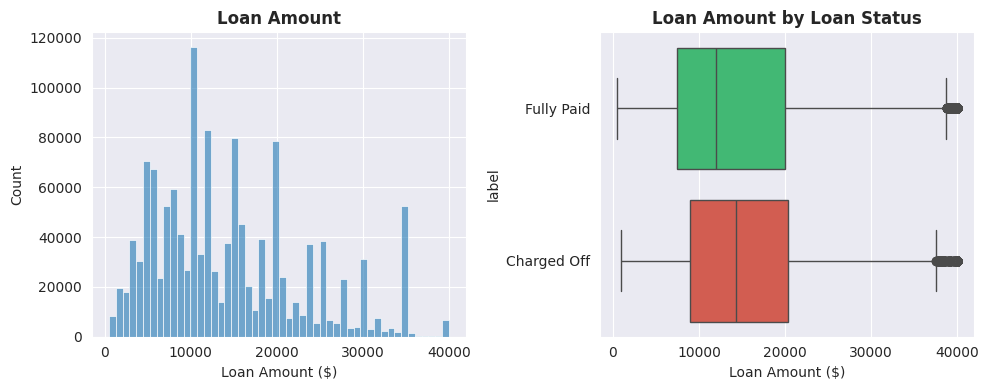

In [ ]:
# Loan amount histogram and boxplot
fig1, ax1 = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(
    data=plot_df, x='loan_amnt',
    bins=50, alpha=0.6, ax=ax1[0]
)
ax1[0].set_title('Loan Amount', fontweight='bold')
ax1[0].set_xlabel('Loan Amount ($)')
ax1[0].set_ylabel('Count')

sns.boxplot(
    data=plot_df, x='loan_amnt', y='label',
    palette=palette, ax=ax1[1], legend=False
)
ax1[1].set_title('Loan Amount by Loan Status', fontweight='bold')
ax1[1].set_xlabel('Loan Amount ($)')

plt.tight_layout()
plt.savefig('../img/loan_amount_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


/tmp/ipykernel_41393/1488351289.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


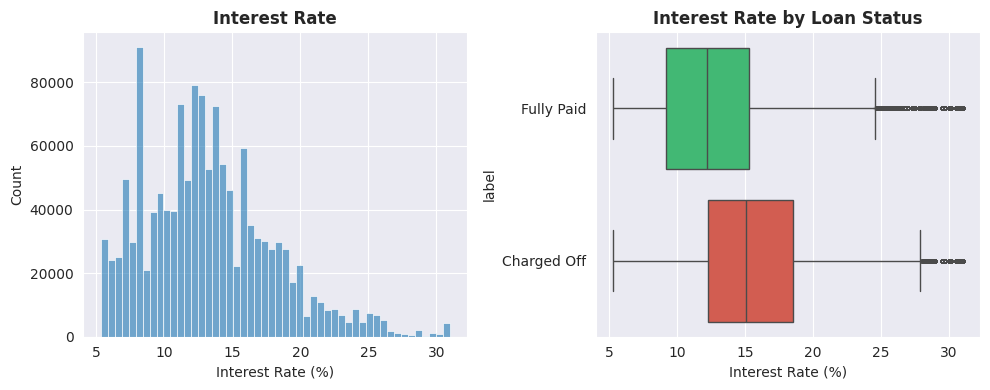

In [ ]:
# Interest rate histogram and boxplot
fig2, ax2 = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(
    data=plot_df, x='int_rate',
    bins=50, alpha=0.6, ax=ax2[0]
)
ax2[0].set_title('Interest Rate', fontweight='bold')
ax2[0].set_xlabel('Interest Rate (%)')
ax2[0].set_ylabel('Count')

sns.boxplot(
    data=plot_df, x='int_rate', y='label',
    palette=palette, ax=ax2[1], legend=False,
    flierprops=dict(marker='o', markersize=2, alpha=0.3)
)
ax2[1].set_title('Interest Rate by Loan Status', fontweight='bold')
ax2[1].set_xlabel('Interest Rate (%)')

plt.tight_layout()
plt.savefig('../img/interest_rate_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_41393/3865733124.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


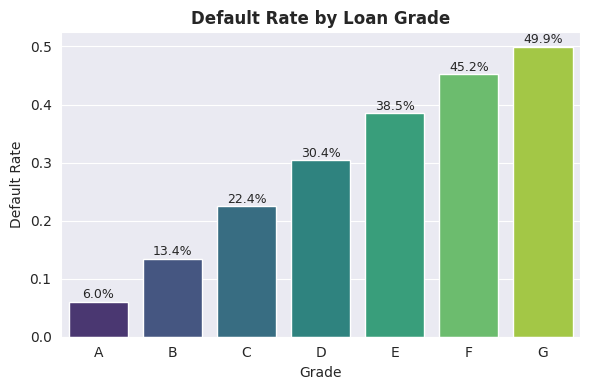

In [ ]:
# Default Rate by Loan Grade
fig3, ax = plt.subplots(figsize=(6, 4))

sns.barplot(
    data=grade_default, x='grade', y='default_rate',
    palette='viridis', ax=ax
)
ax.set_title('Default Rate by Loan Grade', fontweight='bold')
ax.set_xlabel('Grade')
ax.set_ylabel('Default Rate')

for bar, (_, row) in zip(ax.patches, grade_default.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.001,
        f"{row['default_rate']*100:.1f}%",
        ha='center', va='bottom', fontsize=9
    )

plt.tight_layout()
plt.savefig('../img/default_rate_by_grade.png', dpi=150, bbox_inches='tight')
plt.show()

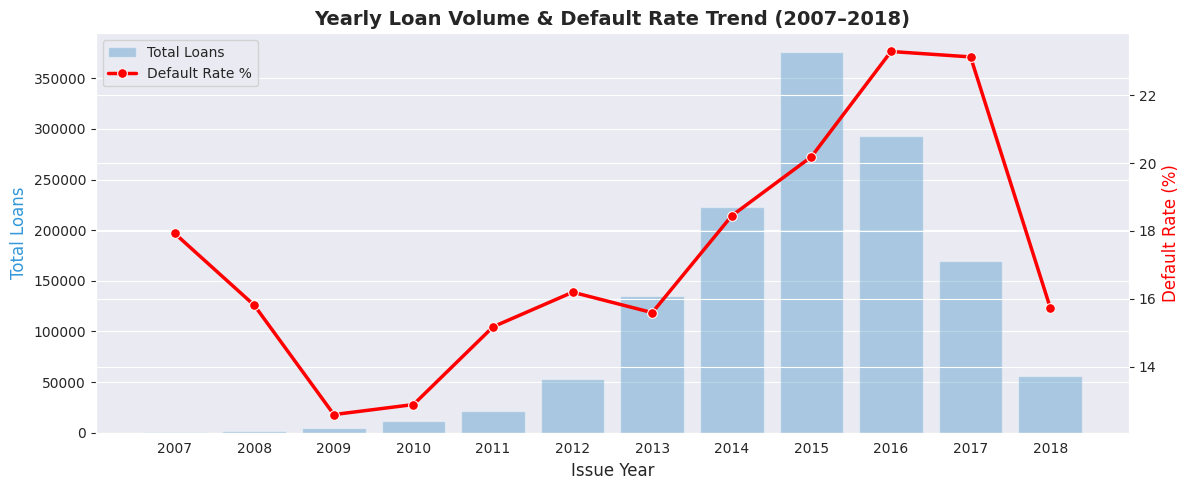

In [ ]:
# Calculate yearly numbers of loan and default statuses
yearly = (
    accepted_df
    .with_columns(
        pl.col("issue_d")
          .str.to_date(format="%b-%Y")
          .dt.year()
          .alias("issue_year")
    )
    .group_by("issue_year")
    .agg([
        pl.col("target").count().alias("total_loans"),
        pl.col("target").sum().alias("defaults")
    ])
    .with_columns(
        (pl.col("defaults") / pl.col("total_loans") * 100).alias("default_rate")
    )
    .sort("issue_year")
    .to_pandas()
)


# Convert year to string so bars spread across x-axis
yearly["issue_year"] = yearly["issue_year"].astype(str)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

# Plot: total loans on ax1
sns.barplot(
    data=yearly,
    x="issue_year",
    y="total_loans",
    alpha=0.4,
    color="#3498db",
    label="Total Loans",
    ax=ax1
)

# Plot: default rate on ax2
sns.lineplot(
    data=yearly,
    x="issue_year",
    y="default_rate",
    color="red",
    linewidth=2.5,
    marker="o",
    markersize=7,
    label="Default Rate %",
    ax=ax2
)

# Labels
ax1.set_xlabel("Issue Year", fontsize=12)
ax1.set_ylabel("Total Loans", fontsize=12, color="#3498db")
ax2.set_ylabel("Default Rate (%)", fontsize=12, color="red")

# Fix 2: remove ax2's auto legend before merging
ax2.get_legend().remove()

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Yearly Loan Volume & Default Rate Trend (2007–2018)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("../img/yearly_trend.png", dpi=150, bbox_inches="tight")
plt.show()

### emp_length
emp_length: Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.
$\rightarrow$ Replace $(<1, 0)$, $(10+, 10)$, and remove null rows

Text(0, 0.5, 'Charge Off Rate (%)')

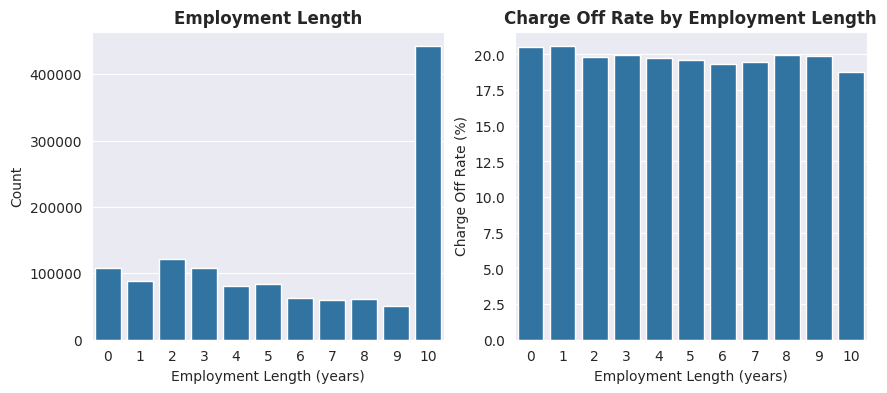

In [ ]:
# Compute charge off rate by emp_length
emp_default = (
    accepted_df 
    .group_by("emp_length")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("emp_length")
    .to_pandas()
)

plot_emp = accepted_df.select(["emp_length", "target"]).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: count plot
sns.countplot(
    data=plot_emp,
    x="emp_length",
    ax=axes[0]
)
axes[0].set_title("Employment Length", fontweight="bold")
axes[0].set_xlabel("Employment Length (years)")
axes[0].set_ylabel("Count")

# Right: charge off rate
sns.barplot(
    data=emp_default,
    x="emp_length",
    y="chargeoff_rate",
    ax=axes[1]
)
axes[1].set_title("Charge Off Rate by Employment Length", fontweight="bold")
axes[1].set_xlabel("Employment Length (years)")
axes[1].set_ylabel("Charge Off Rate (%)")

# Save fig
plt.tight_layout()
plt.savefig("../img/emp_length_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### home_ownership
home_ownership: The home ownership status provided by the borrower.

Values: RENT, OWN, MORTGAGE, OTHER

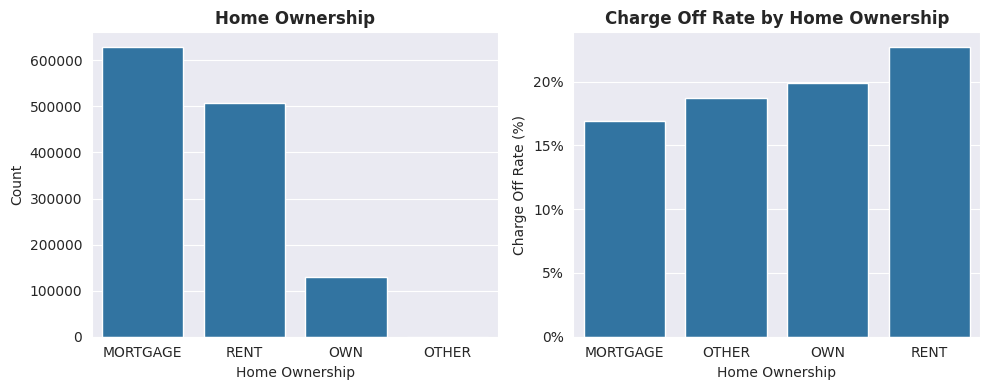

In [ ]:
# Before visualization
home_default = (
    accepted_df 
    .group_by("home_ownership")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("home_ownership")
    .to_pandas()
)

plot_home = accepted_df .select(["home_ownership", "target"]).to_pandas()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_home, x="home_ownership", ax=axes[0])
axes[0].set_title("Home Ownership", fontweight="bold")
axes[0].set_xlabel("Home Ownership")
axes[0].set_ylabel("Count")

sns.barplot(data=home_default, x="home_ownership", y="chargeoff_rate", ax=axes[1])
axes[1].set_title("Charge Off Rate by Home Ownership", fontweight="bold")
axes[1].set_xlabel("Home Ownership")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.savefig("../img/home_ownership_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### verification_status

verification_status: Indicates if income was verified by LendingClub.

Values: Verified, Source Verified, Not Verified

shape: (3, 2)
┌─────────────────────┬────────┐
│ verification_status ┆ count  │
│ ---                 ┆ ---    │
│ str                 ┆ u32    │
╞═════════════════════╪════════╡
│ Source Verified     ┆ 506114 │
│ Not Verified        ┆ 389913 │
│ Verified            ┆ 370772 │
└─────────────────────┴────────┘


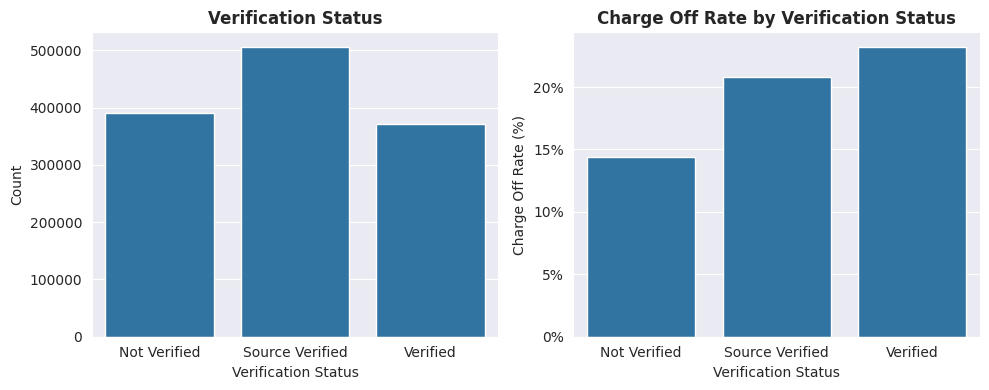

In [ ]:
vfi_default = (
    accepted_df
    .group_by("verification_status")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("verification_status")
    .to_pandas()
)

plot_vfi = accepted_df.select(["verification_status", "target"]).to_pandas()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_vfi, x="verification_status", ax=axes[0])
axes[0].set_title("Verification Status", fontweight="bold")
axes[0].set_xlabel("Verification Status")
axes[0].set_ylabel("Count")

sns.barplot(data=vfi_default, x="verification_status", y="chargeoff_rate", ax=axes[1])
axes[1].set_title("Charge Off Rate by Verification Status", fontweight="bold")
axes[1].set_xlabel("Verification Status")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.savefig("../img/verification_status_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### pub_rec_bankcruptcies

In [ ]:
bktc_default = (
    accepted_df
    .group_by("pub_rec_bankruptcies")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

plot_bktc = accepted_df.select(["pub_rec_bankruptcies", "target"]).to_pandas()
bktc_order = sorted(bktc_default["pub_rec_bankruptcies"].tolist())

shape: (12, 2)
┌──────────────────────┬─────────┐
│ pub_rec_bankruptcies ┆ count   │
│ ---                  ┆ ---     │
│ f64                  ┆ u32     │
╞══════════════════════╪═════════╡
│ 0.0                  ┆ 1114316 │
│ 1.0                  ┆ 142623  │
│ 2.0                  ┆ 7139    │
│ 3.0                  ┆ 1461    │
│ 4.0                  ┆ 361     │
│ 5.0                  ┆ 133     │
│ 6.0                  ┆ 42      │
│ 7.0                  ┆ 14      │
│ 8.0                  ┆ 8       │
│ 9.0                  ┆ 3       │
│ 11.0                 ┆ 1       │
│ 12.0                 ┆ 1       │
└──────────────────────┴─────────┘


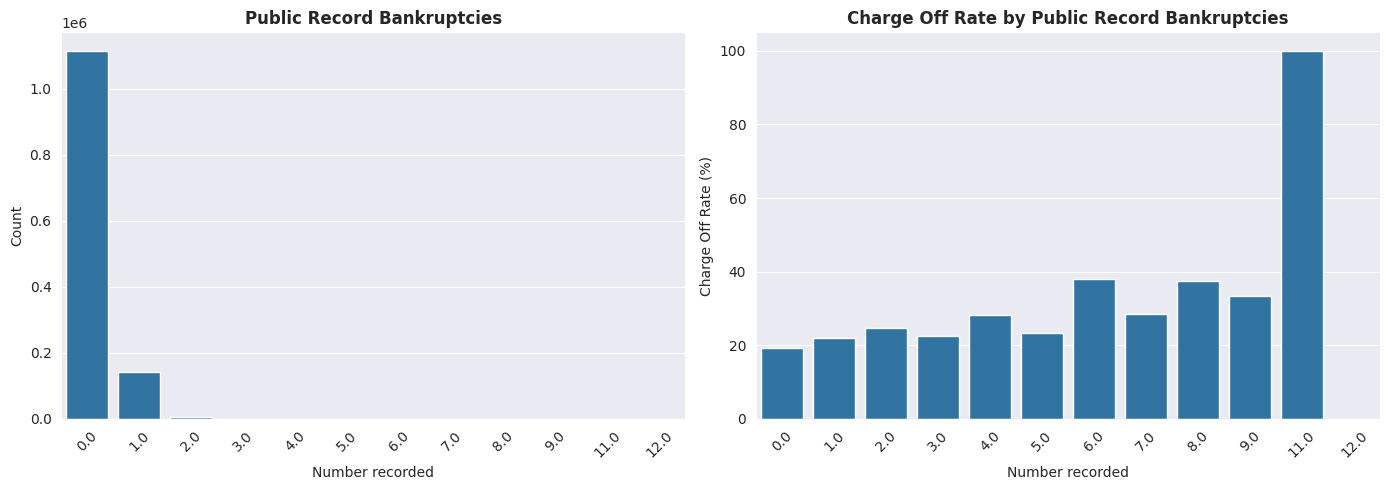

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=plot_bktc, x="pub_rec_bankruptcies", order=bktc_order, ax=axes[0])
axes[0].set_title("Public Record Bankruptcies", fontweight="bold")
axes[0].set_xlabel("Number recorded")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=bktc_default, x="pub_rec_bankruptcies", y="chargeoff_rate",
            order=bktc_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Public Record Bankruptcies", fontweight="bold")
axes[1].set_xlabel("Number recorded")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../img/purpose_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### purpose
purpose: A category provided by the borrower for the loan request.

Values: debt_consolidation, credit_card, home_improvement, etc.

In [ ]:
purpose_default = (
    accepted_df
    .group_by("purpose")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

plot_purpose = accepted_df.select(["purpose", "target"]).to_pandas()
purpose_order = sorted(purpose_default["purpose"].tolist())

shape: (14, 2)
┌────────────────────┬────────┐
│ purpose            ┆ count  │
│ ---                ┆ ---    │
│ str                ┆ u32    │
╞════════════════════╪════════╡
│ debt_consolidation ┆ 737280 │
│ credit_card        ┆ 277310 │
│ home_improvement   ┆ 81205  │
│ other              ┆ 72144  │
│ major_purchase     ┆ 27754  │
│ small_business     ┆ 14924  │
│ medical            ┆ 14244  │
│ car                ┆ 13763  │
│ moving             ┆ 8875   │
│ vacation           ┆ 8366   │
│ house              ┆ 6818   │
│ wedding            ┆ 2243   │
│ renewable_energy   ┆ 876    │
│ educational        ┆ 300    │
└────────────────────┴────────┘


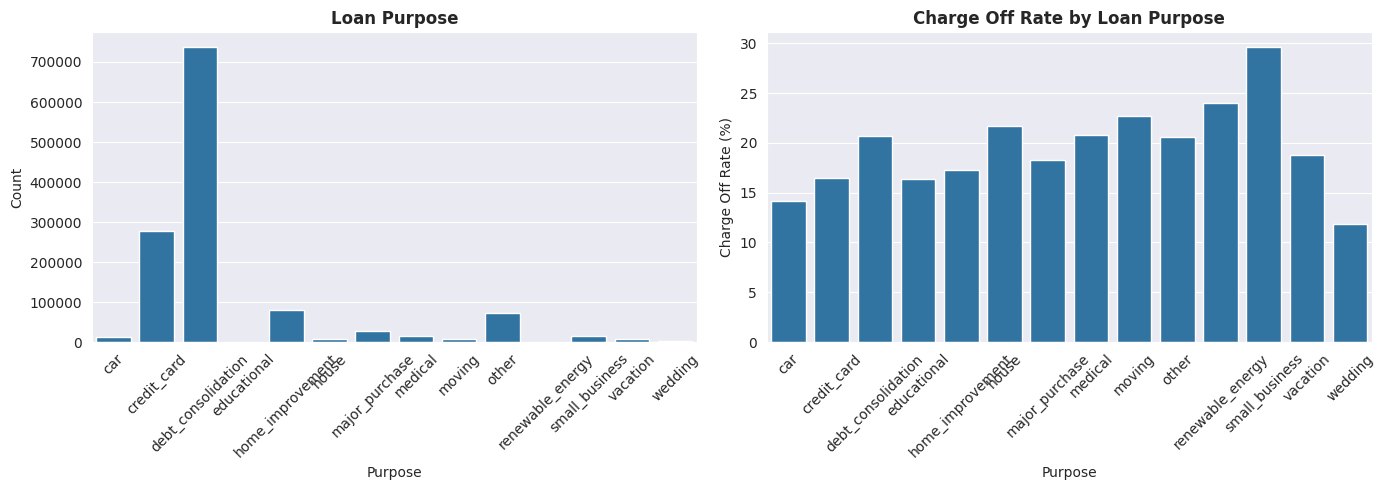

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=plot_purpose, x="purpose", order=purpose_order, ax=axes[0])
axes[0].set_title("Loan Purpose", fontweight="bold")
axes[0].set_xlabel("Purpose")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(data=purpose_default, x="purpose", y="chargeoff_rate",
            order=purpose_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Loan Purpose", fontweight="bold")
axes[1].set_xlabel("Purpose")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../img/purpose_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### annual_inc

annual_inc: The self-reported annual income provided by the borrower.

shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 1.266102e6   │
│ null_count ┆ 0.0          │
│ mean       ┆ 77904.067011 │
│ std        ┆ 71068.992023 │
│ min        ┆ 0.0          │
│ 25%        ┆ 48000.0      │
│ 50%        ┆ 65000.0      │
│ 75%        ┆ 92555.0      │
│ max        ┆ 1.09992e7    │
└────────────┴──────────────┘


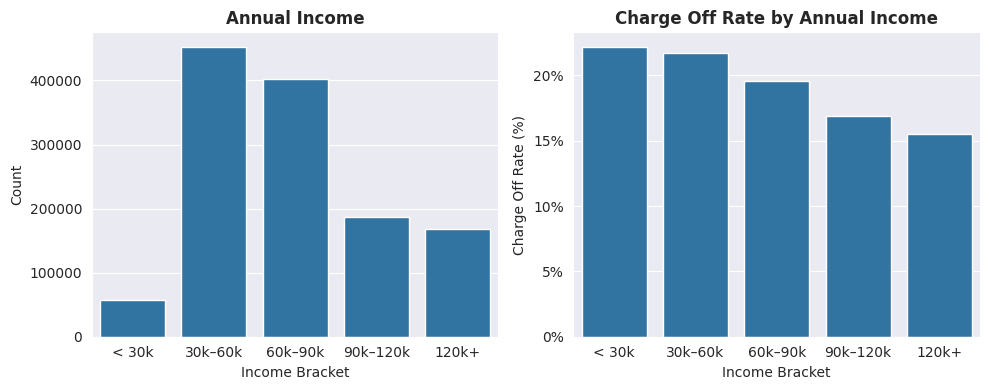

In [ ]:
bracket_order = ["< 30k", "30k–60k", "60k–90k", "90k–120k", "120k+"]

inc_default = (
    accepted_df
    .group_by("income_bracket")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .to_pandas()
)
inc_default["income_bracket"] = pd.Categorical(inc_default["income_bracket"],
                                                categories=bracket_order, ordered=True)
inc_default = inc_default.sort_values("income_bracket")

plot_inc = accepted_df.select(["income_bracket", "target"]).to_pandas()
plot_inc["income_bracket"] = pd.Categorical(plot_inc["income_bracket"],
                                             categories=bracket_order, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(data=plot_inc, x="income_bracket", order=bracket_order, ax=axes[0])
axes[0].set_title("Annual Income", fontweight="bold")
axes[0].set_xlabel("Income Bracket")
axes[0].set_ylabel("Count")

sns.barplot(data=inc_default, x="income_bracket", y="chargeoff_rate",
            order=bracket_order, ax=axes[1])
axes[1].set_title("Charge Off Rate by Annual Income", fontweight="bold")
axes[1].set_xlabel("Income Bracket")
axes[1].set_ylabel("Charge Off Rate (%)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
plt.savefig("../img/annual_inc_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### annual_inc × purpose
Examine how charge off rate varies across income brackets within each loan purpose

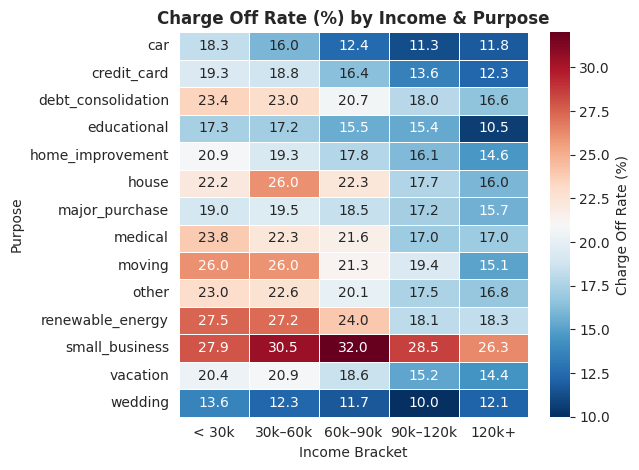

In [ ]:
combo = (
    accepted_df
    .group_by(["income_bracket", "purpose"])
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .to_pandas()
)

combo["income_bracket"] = pd.Categorical(combo["income_bracket"],
                                          categories=bracket_order, ordered=True)
combo = combo.sort_values(["purpose", "income_bracket"])

# charge off rate heatmap (income bracket vs purpose)
heatmap_df = combo.pivot(index="purpose", columns="income_bracket", values="chargeoff_rate")
heatmap_df = heatmap_df[bracket_order]  # enforce column order

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".1f",
    cmap="RdBu_r",
    linewidths=0.5,
    cbar_kws={"label": "Charge Off Rate (%)"}
)
plt.title("Charge Off Rate (%) by Income & Purpose", fontweight="bold")
plt.xlabel("Income Bracket")
plt.ylabel("Purpose")
plt.tight_layout()
plt.savefig("../img/annual_inc_purpose_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

### Debt-to-income_ratio

In [ ]:
dti_loan = accepted_df.select(["target", "dti", "grade"]).to_pandas()
dti_loan.groupby("target")["dti"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1018777.0,17.683830,9.453260,-1.0,11.41,17.04,23.32,999.0
1,247308.0,19.981591,9.821457,0.0,13.50,19.66,26.15,999.0


/tmp/ipykernel_41393/1641291474.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


(0.0, 100.0)

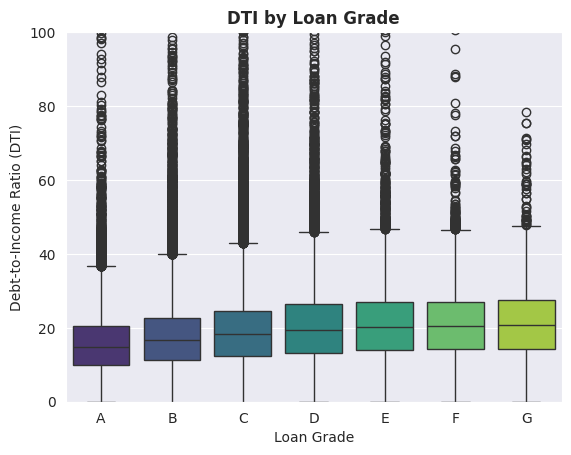

In [ ]:
sns.boxplot(
    data=dti_loan,
    x="grade",
    y="dti",
    order=sorted(plot_df["grade"].dropna().unique()),
    palette="viridis",
)
plt.title("DTI by Loan Grade", fontweight="bold")
plt.xlabel("Loan Grade")
plt.ylabel("Debt-to-Income Ratio (DTI)")
plt.savefig("../img/dti_boxplot.png", dpi=150, bbox_inches="tight")
plt.ylim(0, 100)

### mort_acc
mort_acc: Number of mortgage accounts

**Insight: **Individuals who pay off their loans are more likely to have several mortgage accounts.

In [ ]:
mort_accounts = accepted_df.select(["target", "mort_acc"]).to_pandas()
mort_accounts.groupby("target")["mort_acc"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,980033.0,1.737275,2.030610,0.0,0.0,1.0,3.0,51.0
1,240825.0,1.361275,1.818124,0.0,0.0,1.0,2.0,29.0


Individuals who pay off their loans are more likely to have several mortgage accounts.

## Borrower Segmentation

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [ ]:
# Input features for RL model
features = ['fico_score_avg', 'dti', 'annual_inc', 'emp_length', 'purpose']
# Select features from clean_df
state_df = accepted_df.select(features).clone()
# Drop missing values from the selected features
state_df = state_df.drop_nulls()
# Convert to Pandas DataFrame to use sklearn
state_pd_df = state_df.to_pandas()
# Encode 'purpose' using LabelEncoder
le = LabelEncoder()
state_pd_df['purpose'] = le.fit_transform(state_pd_df['purpose'])
# Scale numeric features
scaler = StandardScaler()
# Apply scaler to all columns of the Pandas DataFrame
X = scaler.fit_transform(state_pd_df)

# K-means clustering on 5 chosen features
# inertia: distance to centroid, silhouette: within cluster and to other cluster
inertia = []
silhouette = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=1)
    labels = kmeans.fit_predict(X)

    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X, labels))

# --- Plot Elbow ---
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")

# --- Plot Silhouette ---
plt.subplot(1,2,2)
plt.plot(K_range, silhouette, marker='o')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

# Choose optimal K that gets max silhouette
optimal_k = K_range[np.argmax(silhouette)]
print("Optimal K:", optimal_k)

KeyboardInterrupt: 

In [ ]:
# Input features for RL model
features = ['fico_score_avg', 'dti', 'annual_inc', 'emp_length', 'purpose']
# Select features from clean_df, clone to ensure an independent DataFrame for modification
state_df = accepted_df.select(features).clone()

# Drop missing values from the selected features
state_df = state_df.drop_nulls()

# Convert to Pandas DataFrame for easier sklearn integration
state_pd_df = state_df.to_pandas()

# Encode 'purpose' using LabelEncoder
le = LabelEncoder()
state_pd_df['purpose'] = le.fit_transform(state_pd_df['purpose'])

# Scale numeric features
scaler = StandardScaler()
# Apply scaler to all columns of the Pandas DataFrame
X = scaler.fit_transform(state_pd_df)

# K-means clustering on 5 chosen features
# inertia: distance to centroid, silhouette: within cluster and to other cluster
inertia = []
silhouette = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=1)
    labels = kmeans.fit_predict(X)

    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X, labels))

# --- Plot Elbow ---
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(K_range, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("K")
plt.ylabel("Inertia")

# --- Plot Silhouette ---
plt.subplot(1,2,2)
plt.plot(K_range, silhouette, marker='o')
plt.title("Silhouette Score")
plt.xlabel("K")
plt.ylabel("Score")

plt.tight_layout()
plt.show()

# Choose optimal K that gets max silhouette
optimal_k = K_range[np.argmax(silhouette)]
print("Optimal K:", optimal_k)

## Classification Models for Default Prediction

**What to do:**

- Train 3 classifiers on the default prediction task: Logistic Regression, Random Forest, XGBoost
- Handle class imbalance using class weighting (`class_weight='balanced'`) or SMOTE
- Tune key hyperparameters for RF and XGBoost (n_estimators, max_depth, learning_rate) using cross-validation
- Evaluate on test set: F1, Precision, Recall, AUC-ROC for the default (minority) class
- Extract and plot feature importances from XGBoost - which features drive default prediction most?
- Convert best classifier into a static lending policy: approve if P(default) < threshold, assign rate tier by risk score - then run through `LendingEnv` to get profit/NPL metrics for comparison

**Input needed:** Preprocessed feature matrix + train/test split from EDA - ✅ already available

**Deliverables:**

- Classification metrics table (LR vs RF vs XGBoost): F1, Precision, Recall, AUC
- Feature importance bar chart (top 10 features from XGBoost)
- Static policy metrics from `LendingEnv`: profit, NPL, approval rate (same format as RL methods)

**Deadline:** `[TBD]`

In [ ]:
!pip install bayesian-optimization

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from xgboost import XGBClassifier
from bayes_opt import BayesianOptimization
import shap

In [ ]:
# convert 'term' → integer
X = X.with_columns(
    pl.col("term")
    .str.extract(r"(\d+)", 1)
    .cast(pl.Int64)
)

# convert 'emp_length' → integer
X = X.with_columns(
    pl.when(pl.col("emp_length") == "< 1 year").then(0)
    .when(pl.col("emp_length") == "10+ years").then(10)
    .otherwise(
        pl.col("emp_length")
        .str.extract(r"(\d+)", 1)
        .cast(pl.Int64)
    )
    .alias("emp_length")
)

# encode categorical variables (Polars way)
X = X.with_columns([
    pl.col("grade").cast(pl.Categorical).to_physical().alias("grade"),
    pl.col("purpose").cast(pl.Categorical).to_physical().alias("purpose")
])

# drop unwanted columns
X = X.drop([
    "sub_grade",
    "home_ownership",
    "earliest_cr_line",
    "verification_status"
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y, test_size=0.3)

In [ ]:
"""KFold cross validation with split preservation of sample percentage for each class"""
def stratified_kfold_split(model, X, y, n_fold):
    X, y = X.values, y.values
    skf = StratifiedKFold(n_splits=n_fold, shuffle=True, random_state=42)
    precision_arr = []
    for train_idx, test_idx in skf.split(X, y):
        X_train_fold, X_test_fold, y_train_fold, y_test_fold = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
        model.fit(X_train_fold, y_train_fold)
        preds = model.predict(X_test_fold)
        precision_arr.append(precision_score(preds, y_test))

    return np.array(precision_arr).mean()

"""Black box function"""
def bo_rf_func(n_estimators: int, max_depth: int,
               max_samples: float, max_features: float):

    # create model instance
    params = {"n_estimators": int(n_estimators),
              "max_depth": int(max_depth),
              "max_samples": max_samples,
              "max_features": max_features}
    rf = RandomForestClassifier(n_estimators=params["n_estimators"],
                                max_depth=params["max_depth"],
                                max_samples=params["max_samples"],
                                max_features=params["max_features"])
    score = stratified_kfold_split(rf, X, y, 5)
    return score

def bo_xgb_func(n_estimators: int, max_depth: int,
                    subsample: float, objective: str, eta: float):
    # create model instance
    params = {"n_estimators": int(n_estimators),
              "max_depth": int(max_depth),
              "subsample": subsample,
              "eta": eta}
    xgboost = XGBClassifier(n_estimators=params["n_estimators"],
                            max_depth=params["max_depth"],
                            subsample=params["subsample"],
                            eta=params["eta"], objective="binary:hinge")
    score = stratified_kfold_split(xgboost, X, y, n_fold=5)
    return score

### 1. Random Forest

In [ ]:
X.head()

loan_amnt,term,int_rate,grade,purpose,annual_inc,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,emp_length,fico_score_avg,last_pymnt_amnt,tot_cur_bal,pub_rec_bankruptcies,tax_liens,acc_now_delinq,mort_acc,bc_util,percent_bc_gt_75,num_rev_accts,num_tl_90g_dpd_24m
f64,i64,f64,u32,u32,f64,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
3600.0,36,13.99,1,7,55000.0,5.91,0.0,1.0,7.0,0.0,2765.0,29.7,10,677.0,122.67,144904.0,0.0,0.0,0.0,1.0,37.2,0.0,9.0,0.0
24700.0,36,11.99,1,8,65000.0,16.06,1.0,4.0,22.0,0.0,21470.0,19.2,10,717.0,926.35,204396.0,0.0,0.0,0.0,4.0,27.1,7.7,27.0,0.0
20000.0,60,10.78,3,9,63000.0,10.78,0.0,0.0,6.0,0.0,7869.0,56.2,10,697.0,15813.3,189699.0,0.0,0.0,0.0,5.0,55.9,50.0,7.0,0.0
10400.0,60,22.45,5,10,104433.0,25.37,1.0,3.0,12.0,0.0,21929.0,64.5,3,697.0,10128.96,331730.0,0.0,0.0,0.0,6.0,77.5,60.0,19.0,0.0
11950.0,36,13.44,1,7,34000.0,10.2,0.0,0.0,5.0,0.0,8822.0,68.4,4,692.0,7653.56,12798.0,0.0,0.0,0.0,0.0,91.0,100.0,4.0,0.0


In [ ]:
rf = RandomForestClassifier()
rf.fit(X_train, y_train)
y_preds = rf.predict(X_test)
print("--- Metrics evaluation ---\n")
print(f"Precision score: {precision_score(y_preds, y_test):.3f}")
print(f"Recall score: {recall_score(y_preds, y_test):.3f}")
print(f"F1 score: {f1_score(y_preds, y_test):.3f}")
print(classification_report(y_preds, y_test))

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


--- Metrics evaluation ---

Precision score: 0.643
Recall score: 0.781
F1 score: 0.705
              precision    recall  f1-score   support

           0       0.96      0.91      0.93    337278
           1       0.64      0.78      0.71     66315

    accuracy                           0.89    403593
   macro avg       0.80      0.85      0.82    403593
weighted avg       0.90      0.89      0.90    403593



In [ ]:
rf_bounds = {"n_estimators": (100, 500),
             "max_depth": (10, 100),
             "max_samples": {0.5, 1.0},
             "max_features": {0.1, 1.0}}

rf_bo = BayesianOptimization(f=bo_rf_func, pbounds=rf_bounds, ramdom_state=42)
rf_results = rf_bo.maximize(n_iter=20, init_points=200)

TypeError: BayesianOptimization.__init__() got an unexpected keyword argument 'ramdom_state'

In [ ]:
rf_params = rf_bo.max['params']
rf_params['n_estimators']= int(rf_params['n_estimators'])
rf_params["max_depth"] = int(rf_params["max_depth"])
print(rf_params)

### 2. XGBoost

In [ ]:
xgb = XGBClassifier()
xgb.fit(X_train, y_train)
y_preds = xgb.predict(X_test)
print("--- Metrics evaluation ---\n")
print(f"Precision score: {precision_score(y_preds, y_test):.3f}")
print(f"Recall score: {recall_score(y_preds, y_test):.3f}")
print(f"F1 score: {f1_score(y_preds, y_test):.3f}")
print(classification_report(y_preds, y_test))

In [ ]:
xgb_bounds = {"n_estimators": (100, 500),
             "max_depth": (10, 100),
             "subsample": {0.5, 1.0},
              "eta": (0.001, 1)}

xgb_bo = BayesianOptimization(f=bo_xgb_func, pbounds=xgb_bounds, random_state=42)
xgb_results = xgb_bo.maximize(n_iter=20, init_points=200)

In [ ]:
xgb_params = xgb_bo.max['params']
xgb_params['n_estimators']= int(xgb_params['n_estimators'])
xgb_params["max_depth"] = int(xgb_params["max_depth"])
print(xgb_params)

### K-Fold Validation for Best Params

In [ ]:
X_pd = X.to_pandas()
y_pd = y.to_pandas()

In [ ]:
# store SHAP importances
rf_shap_importance = []
xgb_shap_importance = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feature_names = X_pd.columns

# Random Forest + SHAP
for train_idx, test_idx in cv.split(X_pd, y_pd):
    X_train, X_test = X_pd.iloc[train_idx], X_pd.iloc[test_idx]
    y_train, y_test = y_pd.iloc[train_idx], y_pd.iloc[test_idx]

    model = RandomForestClassifier(**rf_params)
    model.fit(X_train, y_train)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    # classification → take class 1
    if isinstance(shap_values, list):
        shap_values = shap_values[1]

    importance = np.abs(shap_values).mean(axis=0)
    rf_shap_importance.append(importance)

# XGBoost + SHAP
for train_idx, test_idx in cv.split(X_pd, y_pd):
    X_train, X_test = X_pd.iloc[train_idx], X_pd.iloc[test_idx]
    y_train, y_test = y_pd.iloc[train_idx], y_pd.iloc[test_idx]

    model = XGBClassifier(**xgb_params)
    model.fit(X_train, y_train)

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)

    if isinstance(shap_values, list):
        shap_values = shap_values[1]

    importance = np.abs(shap_values).mean(axis=0)
    xgb_shap_importance.append(importance)

In [ ]:
def plot_importance(importance, feature_names, title):
    idx = np.argsort(importance)

    plt.figure()
    plt.barh(range(len(idx)), importance[idx])
    plt.yticks(range(len(idx)), feature_names[idx])
    plt.title(title)
    plt.xlabel("Mean |SHAP value|")
    plt.show()

In [ ]:
rf_importance_mean = np.mean(rf_shap_importance, axis=0)
xgb_importance_mean = np.mean(xgb_shap_importance, axis=0)

# Plot
plot_importance(rf_importance_mean, feature_names, "RF SHAP (CV averaged)")
plot_importance(xgb_importance_mean, feature_names, "XGB SHAP (CV averaged)")

In [ ]:
df_compare = pd.DataFrame({
    "feature": feature_names,
    "RF": rf_importance_mean,
    "XGB": xgb_importance_mean
}).sort_values("XGB", ascending=False)

print(df_compare.head(10))

In [ ]:
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# result = {"model": [], "accuracy": [], "precision": [], "recall": [], "f1": []}

# X_pd = X.to_pandas()
# y_pd = y.to_pandas()

# # Random Forest + SHAP
# for train_idx, test_idxin cv.split(X, y):
#     X_train, X_test = X_pd.iloc[train_idx], X_pd.iloc[test_idx]
#     y_train, y_test = y_pd.iloc[train_idx], y_pd.iloc[test_idx]
#     best_rf = RandomForestClassifier(**rf_params)
#     best_rf.fit(X.iloc[train_idx], y.iloc[train_idx])
#     rf_preds = best_rf.predict(X.iloc[test_idx])
#     # Update result
#     result["model"].append("Random Forest")
#     result["accuracy"].append(accuracy_score(rf_preds, y.iloc[test_idx]))
#     result["precision"].append(precision_score(rf_preds, y.iloc[test_idx]))
#     result["recall"].append(recall_score(rf_preds, y.iloc[test_idx]))
#     result["f1"].append(f1_score(rf_preds, y.iloc[test_idx]))

# # XGBoost model
# best_xgb = XGBClassifier(**xgb_params)
# for (train_idx, test_idx), i in zip(cv.split(X, y), range(5)):
#     best_xgb.fit(X.iloc[train_idx], y.iloc[train_idx])
#     xgb_preds = best_xgb.predict(X.iloc[test_idx])
#     # Update result
#     result["model"].append("XGBoost")
#     result["accuracy"].append(accuracy_score(xgb_preds, y.iloc[test_idx]))
#     result["precision"].append(precision_score(xgb_preds, y.iloc[test_idx]))
#     result["recall"].append(recall_score(xgb_preds, y.iloc[test_idx]))
#     result["f1"].append(f1_score(xgb_preds, y.iloc[test_idx]))


## Unified Evaluation - Final Comaprison

**What to do:**

- Collect metrics from all 4 methods (Tasks 3, 4, 5 + baseline ✅) into one results table
- Build profit-risk tradeoff chart: plot cumulative profit vs NPL ratio for all 4 methods on one figure
- Write the Results & Discussion section of the paper:
    - Does the Constrained DQN outperform the bandit baseline on NPL compliance?
    - Does the penalty (Method 2 vs 3) make a meaningful difference?
    - Does the RL approach outperform the static classifier policy in profit?
    - What do the findings mean for a real bank's compliance team?

**Input needed:** Metrics from Tasks 3, 4, 5 - ⚠️ must wait for all three

**Deliverables:**

- Unified results table (all 4 methods, all metrics)
- Profit-risk tradeoff plot
- Written Results & Discussion section (draft)

**Deadline:** `[TBD - last task, after all others]`